# Literal two-spin Lindblad physical workload

This following resource study fixes the interacting chain at **n=2, r=69, Z0 and 15,756 complete trials**. Every trial retains all 209 resets, input gates, damping halves and four final readouts. The realized score is +1/−1; all other system/environment records are ignored. There is no algorithm postselection.

This notebook checks the saved source/QASM identities and reruns one bounded, literal four-wire source density check. Actual Clifford+T synthesis and serialized physical reports are **loaded** from the generated bundle; the large trial population and hardware schedule are unexecuted. The n3/r134 and n4/r211 ensemble-cap rejections and unused family allocations stay explicit. No native estimate, new synthesis, GPU or remote run starts here.

In [1]:
from pathlib import Path
from fractions import Fraction
import hashlib, importlib.metadata, json, math, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

root=Path.cwd()
local=(root/"lindblad_physical_workload.py").is_file()
if not local and root.name=="notebooks" and (root.parent/"src/openquantum/simulation/lindblad_physical_workload.py").is_file():
    root=root.parent
if not local and (root/"src/openquantum/simulation/lindblad_physical_workload.py").is_file():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import lindblad_physical_workload as lp
    from openquantum.simulation import lindblad_workload as lw
    from openquantum import instrument_resources as ir
    asset_dir=root/"assets/generated/simulation/lindblad-physical"
else:
    sys.path.insert(0,str(root))
    import lindblad_physical_workload as lp
    import lindblad_workload as lw
    import instrument_resources as ir
    asset_dir=root
# Restore image output even if another imported artifact used the Agg backend.
get_ipython().run_line_magic("matplotlib","inline")

manifest=json.loads((asset_dir/"manifest.json").read_text())
assert platform.python_version()==manifest["python"], "Use the recorded locked Python runtime."
results=json.loads((asset_dir/"results.json").read_text())
prepared=results["prepared"]
assert prepared is not None, "The recorded preparation stage must complete before this evidence notebook runs."
profiles=results["physical_profiles"]
assert len(profiles)==2
assert {r["profile"]["physical_error_rate"] for r in profiles}=={1e-3,1e-4}
family=results["family"]
family_records=list(family.values()) if isinstance(family,dict) else family
for name,expected in manifest["artifacts_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for name,expected in manifest["source_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for module in (lp,lw,ir):
    path=Path(module.__file__)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==manifest["source_sha256"][path.name], path.name
for name,expected in manifest["packages"].items():
    assert importlib.metadata.version(name)==expected, name
limits=ir.InstrumentLimits(**prepared["limits"])
assert limits.max_qubits==4 and limits.source_operations==20000
assert limits.synthesized_operations==limits.validation_operations==500000

def table(frame):
    display(frame.style.hide(axis="index").format(precision=8,na_rep="—"))
def fraction(record):
    return Fraction(record["numerator"],record["denominator"])
def point(report):
    points=report.get("pareto_points",[])
    return min(points,key=lambda p:(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"])) if points else None
print("Saved source/package/artifact hashes and the four-wire density limits verified.")

Saved source/package/artifact hashes and the four-wire density limits verified.


## Fresh literal source check

The source keeps $H=0.6Z_0Z_1+0.35(X_0+X_1)$, intended damping rates 0.8/0.5, $t=1$, +i/+ input and all literal Strang components. The fresh density calculation evaluates the complete source circuit through the existing checker. An independent GKSL matrix exponential supplies the target mean; its dense matrix is a classical reference, never a quantum gate.

The saved routed and actual Clifford+T answers are numerical instrument checks. They do not prove the representation or SDK norm reserves. The normalization trace is not a postselection probability.

stage,Z0
GKSL reference,0.79113374
Fresh literal source,0.79114000
Saved routed,0.79114000
Saved actual Clifford+T,0.79114022


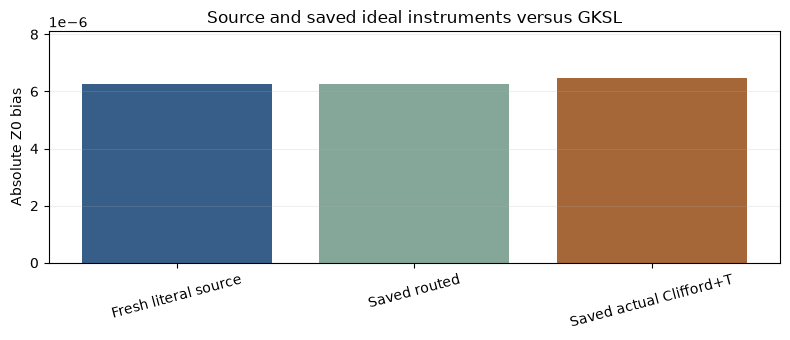

In [2]:
task=lw.ChainTask(2)
assert lw.select_steps(task)==69
assert lw.output_contract()["complete_trials_per_case"]==15756
source=lw.build_chain_circuit(2,task.time,task.J,task.hx,task.rates,69,2,"product",observable="Z")
assert source.num_qubits==source.num_clbits==4
assert source.count_ops()["reset"]==209 and source.count_ops()["measure"]==4
fresh=ir.simulate_trial(source,0,{},limits=limits)
reference=lw.reference_density(task)
observable=lw.on_wire(lw.Z,0,2)
exact=float(np.trace(observable@reference).real)
assert abs(fresh["mean"]-prepared["source_instrument_check"]["mean"])<1e-10
assert abs(fresh["mean"]-exact)<=float(lw.uniform_split_bound(task,69))+1e-10
assert abs(fresh["acceptance_probability"]-1)<1e-10
answers=[{"stage":"GKSL reference","Z0":exact},
         {"stage":"Fresh literal source","Z0":fresh["mean"]},
         {"stage":"Saved routed","Z0":prepared["routed_instrument_check"]["mean"]},
         {"stage":"Saved actual Clifford+T","Z0":prepared["clifford_t_instrument_check"]["mean"]}]
table(pd.DataFrame(answers))
fig,ax=plt.subplots(figsize=(8,3.5))
labels=[r["stage"] for r in answers[1:]]
ax.bar(labels,[max(abs(r["Z0"]-exact),1e-16) for r in answers[1:]],color=["#365e88","#85a79a","#a56737"])
ax.set(ylim=(0,max(abs(r["Z0"]-exact) for r in answers[1:])*1.25),ylabel="Absolute Z0 bias",title="Source and saved ideal instruments versus GKSL")
ax.ticklabel_format(axis="y",style="sci",scilimits=(-3,3))
ax.tick_params(axis="x",rotation=15)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Separate approximation stages

The per-output target is 0.05: splitting allowance 0.01, realization allowance 0.01 and statistics 0.03. The uniform source bound refers to exact decimal parameters and ideal exact substeps. Stored binary64 sub-times and damping angles need a separate representation premise. SDK control/routing and guarded actual Ross–Selinger synthesis are further stages.

The requested whole-circuit synthesis allowance is $5\times10^{-5}$. The saved actual guarded sum, representation reserve $10^{-7}$ and SDK reserve $10^{-7}$ form a conditional coherent error $\eta$. Ideal reset/discard contraction gives unconditional Z0 mean change at most $2\eta$; this deterministic bias is not multiplied by the trial count. Neither reserve is inferred from density agreement. Exact rational input/H-angle discrepancies have narrower coverage than a full representation certificate.

stage,absolute_Z0_error,scope
Uniform splitting bound,0.00984443,exact-substep source
Realization proposal,0.00001231,actual numerical synthesis + two conditional reserves
Statistics allowance,0.03000000,"15,756 independent complete scores"


guarded_actual_synthesis_error,representation_norm_reserve,SDK_norm_reserve,exact_H_angle_component_upper,representation_reserve_certified
0.00000595,0.00000010,0.00000010,0.00000000,False


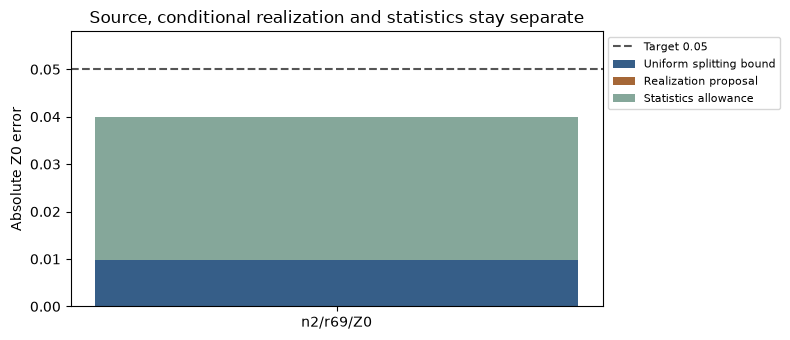

In [3]:
c=prepared["error_contract"]
representation=prepared["representation_check"]
assert fraction(c["splitting_bias_exact"])==lw.uniform_split_bound(task,69)
assert fraction(c["whole_realization_error_exact"])*2<=Fraction(1,100)
assert c["absolute_Z0_error_upper_proposal"]<=.05
assert c["representation_norm_reserve_scenario"]==c["SDK_control_routing_norm_reserve_scenario"]==1e-7
assert c["reserve_is_inferred_from_density_agreement"] is False
assert c["coherent_error_is_stochastic_failure"] is False
assert c["full_representation_certificate"] is False
budget=[{"stage":"Uniform splitting bound","absolute_Z0_error":c["splitting_bias_upper"],"scope":"exact-substep source"},
        {"stage":"Realization proposal","absolute_Z0_error":c["realization_Z0_bias_upper_proposal"],"scope":"actual numerical synthesis + two conditional reserves"},
        {"stage":"Statistics allowance","absolute_Z0_error":c["statistical_absolute_error"],"scope":"15,756 independent complete scores"}]
table(pd.DataFrame(budget))
table(pd.DataFrame([{"guarded_actual_synthesis_error":c["guarded_actual_synthesis_error"],
                    "representation_norm_reserve":c["representation_norm_reserve_scenario"],
                    "SDK_norm_reserve":c["SDK_control_routing_norm_reserve_scenario"],
                    "exact_H_angle_component_upper":representation["Hamiltonian_angle_coherent_error_component_upper"],
                    "representation_reserve_certified":representation["representation_reserve_is_certified"]}]))
fig,ax=plt.subplots(figsize=(8,3.5))
bottom=0
for row,color in zip(budget,("#365e88","#a56737","#85a79a")):
    ax.bar(["n2/r69/Z0"],[row["absolute_Z0_error"]],bottom=bottom,label=row["stage"],color=color,width=.45)
    bottom+=row["absolute_Z0_error"]
ax.axhline(.05,color="#555555",linestyle="--",label="Target 0.05")
ax.set(ylabel="Absolute Z0 error",ylim=(0,.058),title="Source, conditional realization and statistics stay separate")
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1,1))
fig.tight_layout()
plt.show()

## Whole trial population and unused family allocations

All 15,756 trials run the complete schedule. Each has 209 source resets and four readouts, plus 11 additional reserved workspace/bridge initializations in the physical model. The implementation retains the original literal r69 source rather than removing commuting damping halves.

The family statistics allowance remains 0.005, or $1/600$ per case. Physical faults and factory readiness each receive 0.0025 for the family, or $1/1200$ per case. The n2 slice uses its unchanged shares. n3/r134 and n4/r211 reject in the 256-branch source ensemble and have no physical implementation; their allocations are not reassigned. There is no simultaneous hardware-confidence claim for all three outputs.

systems,steps,complete_trials,status,physical_status
2,69,15756,implemented_four_wire_density_slice,computed_conditional_instrument_surface_code_model
3,134,15756,ensemble_branch_cap_exceeded,unimplemented_reserved_allocation
4,211,15756,ensemble_branch_cap_exceeded,unimplemented_reserved_allocation


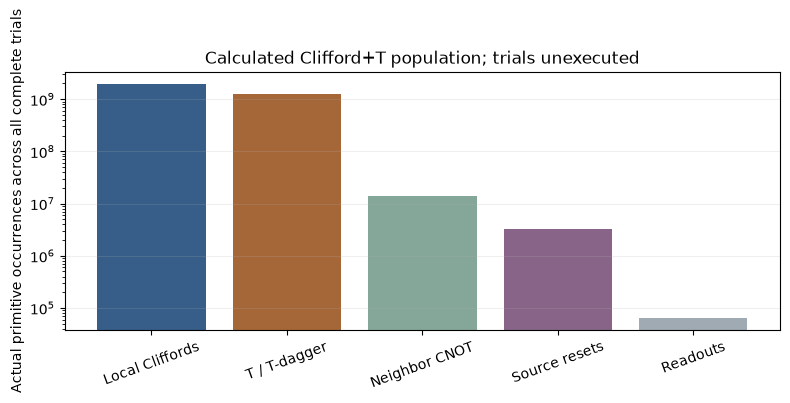

In [4]:
w=prepared["complete_workload"]
counts=w["primitive_counts_per_complete_trial"]
assert w["complete_trials"]==w["complete_attempts"]==15756
assert w["algorithm_retry_cap"]==1 and w["postselection"]=="none"
assert w["reset_per_trial"]==counts["reset"]==209
assert w["readout_per_trial"]==counts["measure"]==4
assert w["source_resets_all_trials"]==3293004 and w["source_readouts_all_trials"]==63024
assert w["workspace_startup_initializations_all_trials"]==11*15756
for name,count in counts.items():
    assert w["primitive_counts_all_trials"][name]==count*15756
allocations=prepared["family_allocations"]
assert allocations["unused_cases_reallocated"] is False
assert allocations["family_physical_confidence_implemented"] is False
for n,allocation in allocations["case_allocations"].items():
    assert fraction(allocation["statistical_failure_exact"])==Fraction(1,600)
    assert fraction(allocation["physical_failure_exact"])==Fraction(1,1200)
    assert fraction(allocation["factory_availability_failure_exact"])==Fraction(1,1200)
family_table=[{"systems":r["n_system"],"steps":r["selected_steps"],"complete_trials":r["complete_trials"],
               "status":r["status"],"physical_status":(", ".join(dict.fromkeys(p["status"] for p in profiles)) if r["n_system"]==2 else r.get("physical_status",r["status"]))} for r in family_records]
table(pd.DataFrame(family_table))
groups={"Local Cliffords":sum(counts.get(g,0) for g in ("h","x","y","z","s","sdg")),
        "T / T-dagger":sum(counts.get(g,0) for g in ("t","tdg")),
        "Neighbor CNOT":counts.get("cx",0),"Source resets":counts["reset"],"Readouts":counts["measure"]}
fig,ax=plt.subplots(figsize=(8,3.7))
ax.bar(groups.keys(),[v*15756 for v in groups.values()],color=["#365e88","#a56737","#85a79a","#876488","#a0aab2"])
ax.set(yscale="log",ylabel="Actual primitive occurrences across all complete trials",title="Calculated Clifford+T population; trials unexecuted")
ax.tick_params(axis="x",rotation=20)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Two frozen serialized physical profiles

The reports keep physical error $10^{-3}$ or $10^{-4}$ and the default controller error $10^{-15}$ per decision. These are alternative physical assumptions for the same complete task. Gates/initialization take 100 ns, readout 500 ns, code cycles 1,000 ns and controller reaction 10,000 ns. Reset/readout, startup, idle exposure, trial dispatch, routing, neighboring transport, injection/correction and complete factory retries are charged. Peak space adds one native factory to 15 reserved logical patches.

The points below are conditional QDK/ledger calculations, not executed hardware schedules. Infeasibility or a query/instruction/time cap remains explicit. Protected parity geometry, tracked frames and factory handoff remain assumptions. The model is separate from the frozen Grover/PSSPC baseline.

physical_error,status,distance,peak_physical_qubits,all_trial_hours,Pareto_points
0.00100000,computed_conditional_instrument_surface_code_model,33,816375,3336.89819486,3
0.00010000,computed_conditional_instrument_surface_code_model,17,204835,1928.88650371,3


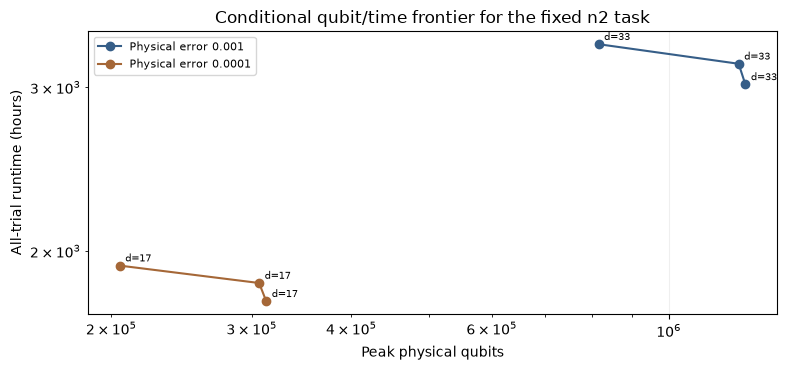

In [5]:
rows=[]
for report in profiles:
    p=report["profile"]
    assert p["physical_error_rate"] in (1e-3,1e-4)
    assert p["controller_failure_per_decision"]==1e-15
    best=point(report)
    rows.append({"physical_error":p["physical_error_rate"],"status":report["status"],
                 "distance":best["data_code_distance"] if best else None,
                 "peak_physical_qubits":best["peak_physical_qubits"] if best else None,
                 "all_trial_hours":best["worst_case_runtime_all_attempts_ns"]/3.6e12 if best else None,
                 "Pareto_points":len(report.get("pareto_points",[]))})
table(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(8,3.8))
plotted=False
for report,color in zip(profiles,("#365e88","#a56737")):
    points=report.get("pareto_points",[])
    if points:
        plotted=True
        ax.plot([p["peak_physical_qubits"] for p in points],[p["worst_case_runtime_all_attempts_ns"]/3.6e12 for p in points],
                "o-",color=color,label=f"Physical error {report['profile']['physical_error_rate']:g}")
        for p in points:
            ax.annotate(f"d={p['data_code_distance']}",(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"]/3.6e12),
                        xytext=(4,3),textcoords="offset points",fontsize=7)
if plotted:
    ax.set(xscale="log",yscale="log")
    ax.legend(fontsize=8)
else:
    ax.text(.5,.5,"No computed feasible profile; see explicit statuses",ha="center",va="center",transform=ax.transAxes)
ax.set(xlabel="Peak physical qubits",ylabel="All-trial runtime (hours)",title="Conditional qubit/time frontier for the fixed n2 task")
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

## Fault components and factory readiness

Physical fault components add within the engineering model. Native factory output quality is counted once; the availability of enough accepted factory pipelines has its own $1/1200$ case budget. Complete pipeline retries include timing and controller work. A controller contribution is a model term, not a lower bound on actual hardware failure.

For the minimum-space Pareto point in each computed profile, the following checks compare the saved component sum and its physical allocation. The readiness bound is shown separately rather than folded into synthesis or algorithm acceptance.

physical_error,physical_fault_model,physical_budget,readiness_model,readiness_budget,factory_retry_cap
0.00100000,0.00033476,0.00083333,0.00001231,0.00083333,7
0.00010000,0.00016260,0.00083333,0.00001231,0.00083333,7


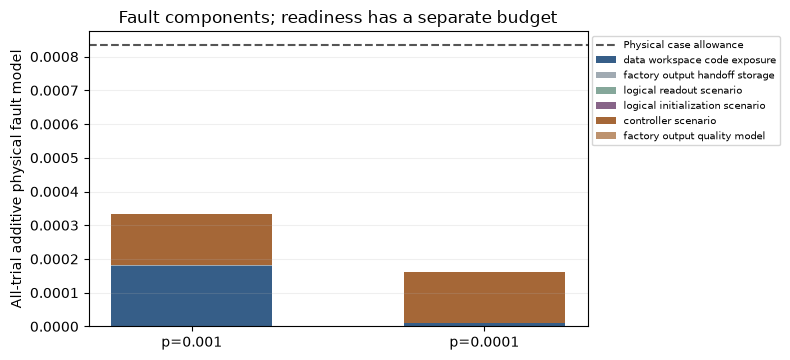

In [6]:
component_names=("data_workspace_code_exposure","factory_output_handoff_storage","logical_readout_scenario",
                 "logical_initialization_scenario","controller_scenario","factory_output_quality_model")
fault_rows=[]
feasible=[]
for report in profiles:
    best=point(report)
    if best:
        feasible.append((report,best))
        components=best["failure_components_all_attempts"]
        assert math.isclose(sum(components.values()),best["full_physical_failure_model"],rel_tol=1e-10,abs_tol=1e-13)
        assert best["full_physical_failure_model"]<=report["physical_failure_budget"]
        assert best["factory_supply"]["availability_failure_union_bound"]<=report["factory_availability_budget"]
        assert best["reserved_logical_patches"]==15
        fault_rows.append({"physical_error":report["profile"]["physical_error_rate"],
                           "physical_fault_model":best["full_physical_failure_model"],
                           "physical_budget":report["physical_failure_budget"],
                           "readiness_model":best["factory_supply"]["availability_failure_union_bound"],
                           "readiness_budget":report["factory_availability_budget"],
                           "factory_retry_cap":best["factory_supply"]["full_pipeline_retry_cap_per_state"]})
    else:
        fault_rows.append({"physical_error":report["profile"]["physical_error_rate"],"status":report["status"]})
table(pd.DataFrame(fault_rows))
fig,ax=plt.subplots(figsize=(8,3.7))
if feasible:
    x=np.arange(len(feasible))
    bottom=np.zeros(len(feasible))
    colors=("#365e88","#a0aab2","#85a79a","#876488","#a56737","#bd926e")
    for name,color in zip(component_names,colors):
        values=np.array([p["failure_components_all_attempts"][name] for _,p in feasible])
        ax.bar(x,values,bottom=bottom,label=name.replace("_"," "),color=color,width=.55)
        bottom+=values
    ax.axhline(float(Fraction(1,1200)),color="#555555",linestyle="--",label="Physical case allowance")
    ax.set(xticks=x,xticklabels=[f"p={r['profile']['physical_error_rate']:g}" for r,_ in feasible])
    ax.legend(fontsize=7,loc="upper left",bbox_to_anchor=(1,1))
else:
    ax.text(.5,.5,"No computed components; see explicit statuses",ha="center",va="center",transform=ax.transAxes)
ax.set(ylabel="All-trial additive physical fault model",title="Fault components; readiness has a separate budget")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()

## Reproduction, provenance and limits

In the checkout use `PYTHONPATH=src python scripts/generate_simulation_lindblad_physical.py`. This notebook loads the resulting native evidence and performs only a bounded source check. For an independent notebook run, save all copied Python sources, manifest/results/CSV, QASM files, lock, license and references beside this notebook.

The fixed run permits one prepared workload, source 20,000 instructions, synthesized/density validation 500,000, one four-wire density check path, two physical profiles and the declared 256-branch diagnostic rejections. Stage and native-query caps are recorded below; candidates are not silently truncated. A prepared whole-circuit stage may make several native rotation-synthesis attempts; the attempt cap is separate from the stage count. Saved sequence hashes identify unseeded native synthesis. Measured-trial QASM omits overall phase; coherent controlled reuse of unitary segments requires source or phase restoration.

The representation/SDK reserves, factory interface, memory/initialization/readout scenarios and hardware calibration have distinct scopes. Offline preprocessing/report wall time, layout certification and decoder throughput remain outside quantum runtime. There is no formal synthesis, full representation or hardware confidence certificate and no claimed quantum advantage.

In [7]:
assert manifest["frozen_before"]==manifest["frozen_after"]
assert manifest["private_cache_distributed"] is False
assert manifest["whole_family_physical_completed"] is False
assert manifest["synthesis_seed"] is None and manifest["transpiler_seed"]==7
assert prepared["hardware_execution"] is False and prepared["formal_confidence_certificate"] is False
assert prepared["complete_workload"]["whole_workload_executed"] is False
assert prepared["actual_synthesis"]["actual_synthesis_sequences_generated"] is True
assert prepared["actual_synthesis"]["preserve_full_unitary"] is True
assert prepared["actual_synthesis"]["transpiler_qubits_initially_zero"] is False
for record in family_records:
    if record["n_system"] in (3,4):
        assert record["physical_estimation_performed"] is False
        assert record["synthesis_performed"] is False
        assert record["family_allocation_reallocated"] is False
assert prepared["family_allocations"]["family_physical_confidence_implemented"] is False
caps=prepared["run_caps"]
assert caps["physical_cases"]==1 and caps["physical_profiles"]==2
assert caps["factory_queries_per_profile"]==caps["surface_code_queries_per_profile"]==24
assert caps["factory_candidates_per_query"]==1000
print("All saved identities, literal trial counts, unused family allocations and unexecuted-workload labels verified.")
print("Recorded package versions:",manifest["packages"])
cap_labels={"prepared_synthesis_stages":"Prepared whole-circuit synthesis stages",
            "native_rotation_synthesis_attempts_upper_bound":"Native rotation-synthesis attempt upper bound"}
table(pd.DataFrame([{"cap":cap_labels.get(name,name.replace("_"," ")),"value":value} for name,value in caps.items() if isinstance(value,int) and not isinstance(value,bool)]))
print("Actual unique rotation targets:",prepared["actual_synthesis"]["unique_rotation_targets"])
observed_attempts=prepared["actual_synthesis"].get("native_rotation_synthesis_attempts")
if observed_attempts is not None:
    assert 0<=observed_attempts<=caps["native_rotation_synthesis_attempts_upper_bound"]
    print("Observed native rotation-synthesis attempts:",observed_attempts)


All saved identities, literal trial counts, unused family allocations and unexecuted-workload labels verified.
Recorded package versions: {'qiskit': '2.6.2', 'qdk': '1.34.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


cap,value
physical cases,1
Prepared whole-circuit synthesis stages,1
Native rotation-synthesis attempt upper bound,3312
physical profiles,2
source instructions,20000
routed and synthesized instructions,500000
density validation instructions,500000
density wires,4
unused family ensemble branches,256
family diagnostic seconds,60


Actual unique rotation targets: 6
Observed native rotation-synthesis attempts: 6
